In [6]:
# --- CONFIGURATION ---
PROJECTION_TYPE = "linear" # Set to "pca" or "linear" to switch between result sets

# Optimization Analysis: Optuna Tuning Gains

Bu notebook, standart parametrelerle eğitilen **Baseline** model ile Optuna tarafından optimize edilen **Tuned** model arasındaki performans farkını analiz eder.

Optimization Comparison (LINEAR):


,Model,Dev nDCG,Test nDCG,Test Top-1,Xeval nDCG
0,Baseline (Before Optuna),82.12,83.93,40.62,69.69
1,Tuned (After Optuna),82.34,85.22,49.38,69.78


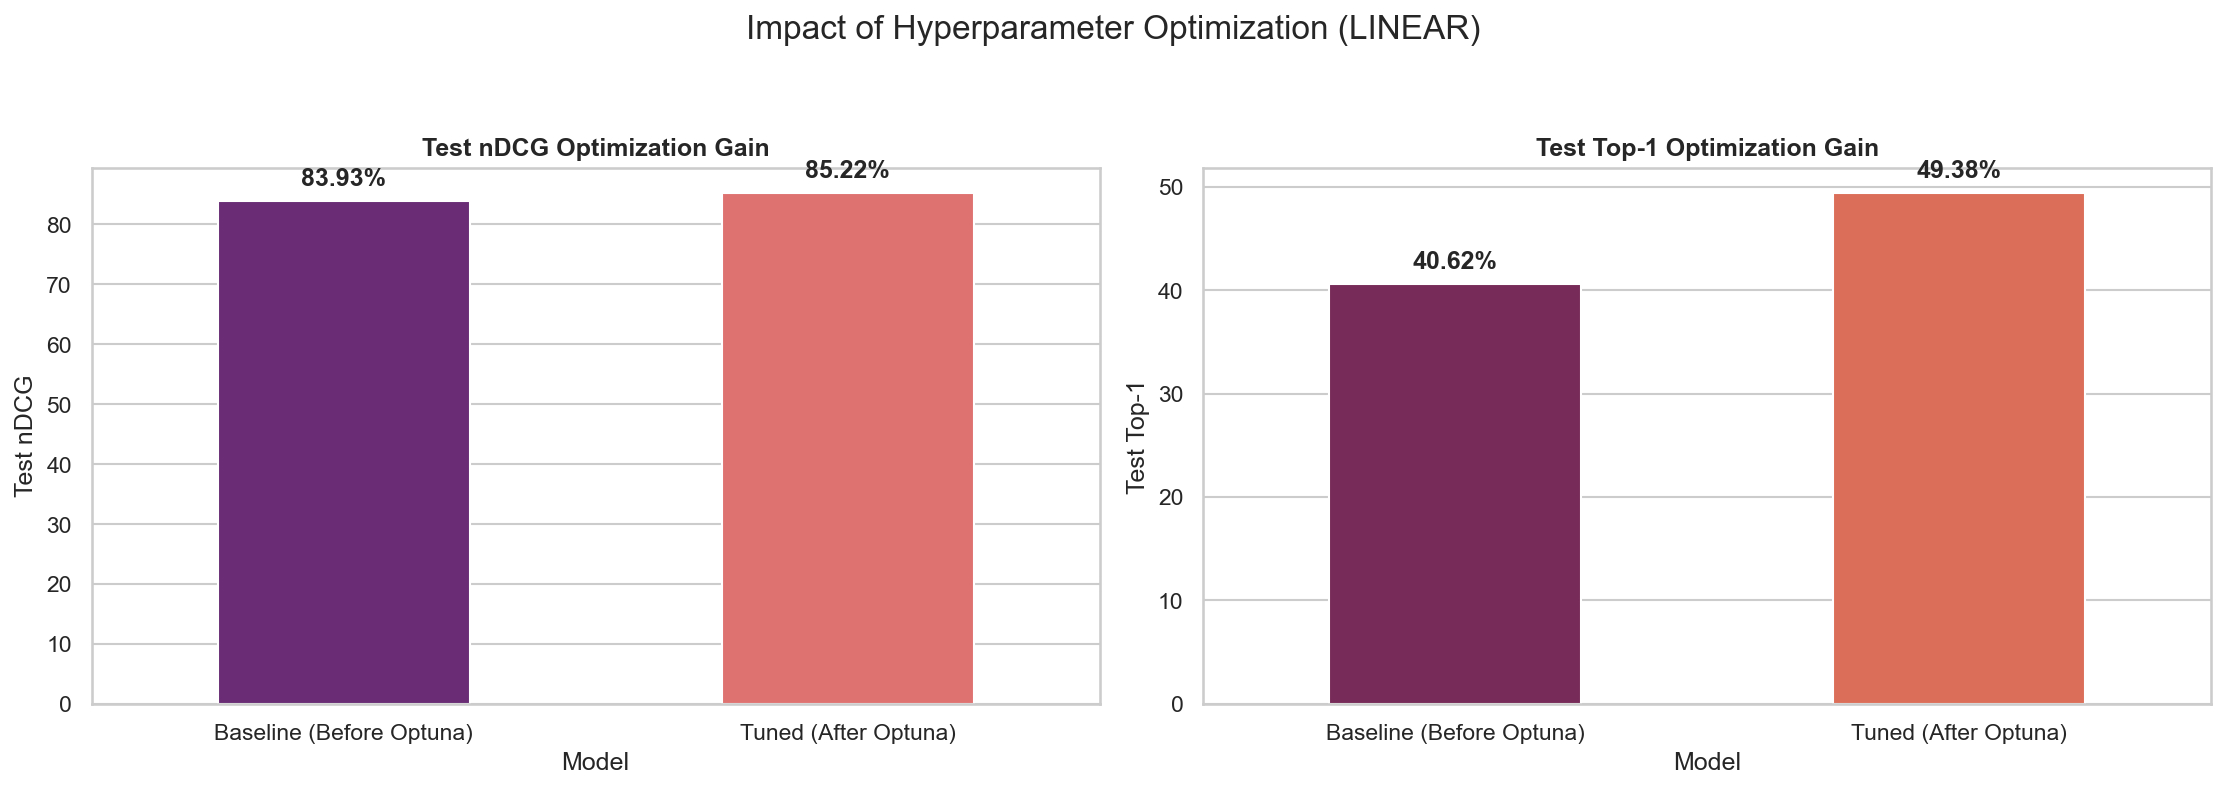

In [7]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 150

def load_summary(path_str):
    path = Path(path_str)
    if path.exists():
        with open(path, 'r') as f:
            return json.load(f)
    return None

base_dir = Path(PROJECTION_TYPE)
paths = {
    'Baseline (Before Optuna)': base_dir / 'baseline/summary.json',
    'Tuned (After Optuna)': base_dir / 'final_model/summary.json'
}

data = {}
for name, path in paths.items():
    summary = load_summary(path)
    if summary:
        data[name] = summary['aggregate'][0]
        
if len(data) == 2:
    rows = []
    for name, agg in data.items():
        rows.append({
            'Model': name,
            'Dev nDCG': agg['best_dev']['ndcg'] * 100,
            'Test nDCG': agg['test']['ndcg'] * 100,
            'Test Top-1': agg['test']['top1'] * 100,
            'Xeval nDCG': agg['xeval']['ndcg'] * 100,
        })
        
    df = pd.DataFrame(rows)
    print(f"Optimization Comparison ({PROJECTION_TYPE.upper()}):")
    display(df.round(2))
    
    metrics = [('Test nDCG', 'magma'), ('Test Top-1', 'rocket')]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    for i, (metric, cmap) in enumerate(metrics):
        ax = axes[i]
        sns.barplot(data=df, x='Model', y=metric, hue='Model', legend=False, palette=cmap, width=0.5, ax=ax)
        ax.set_title(f'{metric} Optimization Gain', fontweight='bold')
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')
                     
    plt.suptitle(f"Impact of Hyperparameter Optimization ({PROJECTION_TYPE.upper()})", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()
else:
    print(f"Results not found for {PROJECTION_TYPE}. Run hyperparam_tuning/run.py first.")